=== Top 10 Features Pushing Churn Risk UP ===
                       Feature  Coefficient  Odds_Ratio
   InternetService_Fiber optic       0.6342      1.8855
       Contract_Month-to-month       0.5829      1.7912
                  TotalCharges       0.5363      1.7096
           StreamingMovies_Yes       0.2009      1.2225
               StreamingTV_Yes       0.2005      1.2220
PaymentMethod_Electronic check       0.1979      1.2188
             OnlineSecurity_No       0.1563      1.1692
                TechSupport_No       0.1315      1.1405
             MultipleLines_Yes       0.1046      1.1103
                 SeniorCitizen       0.0534      1.0549

=== Top 10 Features Pushing Churn Risk DOWN ===
                             Feature  Coefficient  Odds_Ratio
                              tenure      -1.2575      0.2844
                   Contract_Two year      -0.7766      0.4600
                 InternetService_DSL      -0.6486      0.5228
                      MonthlyCharges     

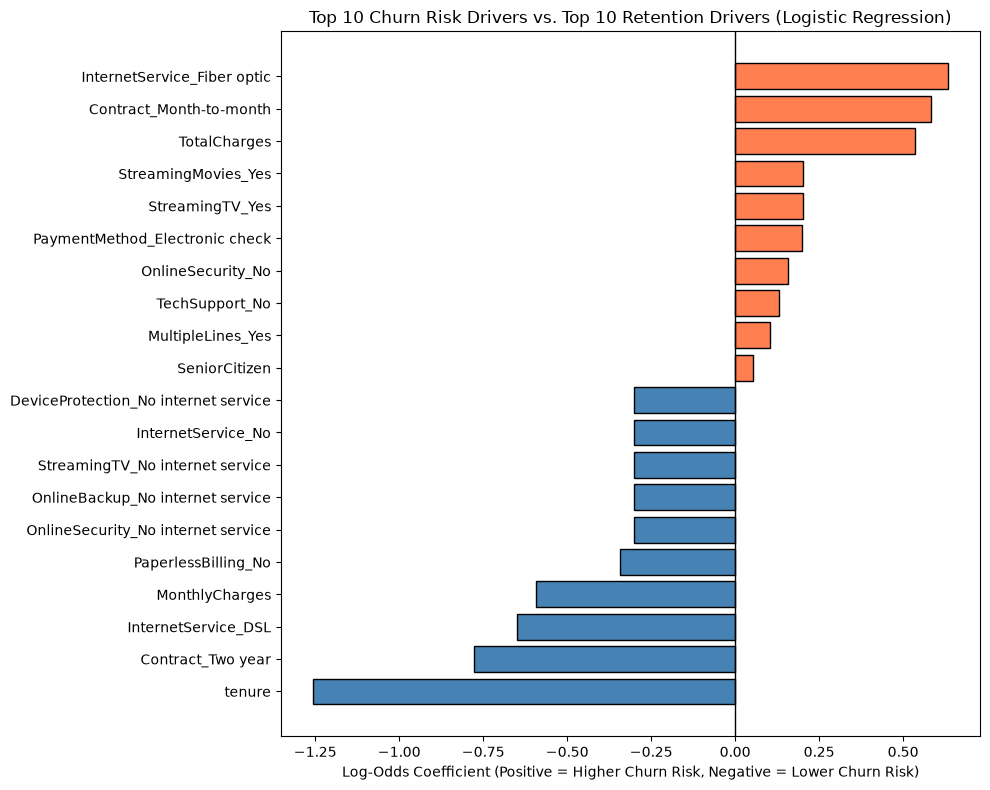

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load and clean data (adjust file path if needed inside notebooks/)
import sqlite3
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
con = sqlite3.connect(":memory:")
df.to_sql("customers", con, index=False)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])

# 2. Separate features (X) and binary target (y)
X = df.drop(columns=["customerID", "Churn", "tenure_group"], errors="ignore")
y = (
    df["Churn"].map({"Yes": 1, "No": 0}).astype(int)
    if pd.api.types.is_string_dtype(df["Churn"])
    else df["Churn"].astype(int)
)

# 3. Same stratified 80/20 split as Ticket 3
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Build and fit the winning Logistic Regression pipeline on X_train
num_cols = X.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            num_cols,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            cat_cols,
        ),
    ]
)

logreg_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

logreg_pipe.fit(X_train, y_train)

# 5. Extract feature names and model coefficients
feature_names = logreg_pipe.named_steps["preprocessor"].get_feature_names_out()
# Clean up prefixes like 'num__' and 'cat__' for readability
clean_names = [name.split("__", 1)[-1] for name in feature_names]

coefs = logreg_pipe.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({
    "Feature": clean_names,
    "Coefficient": coefs,
    "Odds_Ratio": np.exp(coefs),
}).sort_values(by="Coefficient", ascending=False)

print("=== Top 10 Features Pushing Churn Risk UP ===")
print(coef_df.head(10).to_string(index=False, float_format="%.4f"))

print("\n=== Top 10 Features Pushing Churn Risk DOWN ===")
print(coef_df.tail(10).sort_values(by="Coefficient").to_string(index=False, float_format="%.4f"))

# 6. Plot Top 10 Risk-Increasing vs. Top 10 Risk-Decreasing Features
top_up = coef_df.head(10)
top_down = coef_df.tail(10)
plot_df = pd.concat([top_up, top_down]).sort_values(by="Coefficient", ascending=True)

colors = ["steelblue" if c < 0 else "coral" for c in plot_df["Coefficient"]]

plt.figure(figsize=(10, 8))
plt.barh(plot_df["Feature"], plot_df["Coefficient"], color=colors, edgecolor="black")
plt.axvline(0, color="black", linewidth=1)
plt.title("Top 10 Churn Risk Drivers vs. Top 10 Retention Drivers (Logistic Regression)")
plt.xlabel("Log-Odds Coefficient (Positive = Higher Churn Risk, Negative = Lower Churn Risk)")
plt.tight_layout()
plt.show()


In [3]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


=== Training Set (Out-of-Fold CV) Threshold Comparison ===
Best Threshold: 0.33 | Called: 1976 | True Churners: 1106 | Profit: $67,100
0.33 Threshold: 0.33 | Called: 1976 | True Churners: 1106 | Profit: $67,100


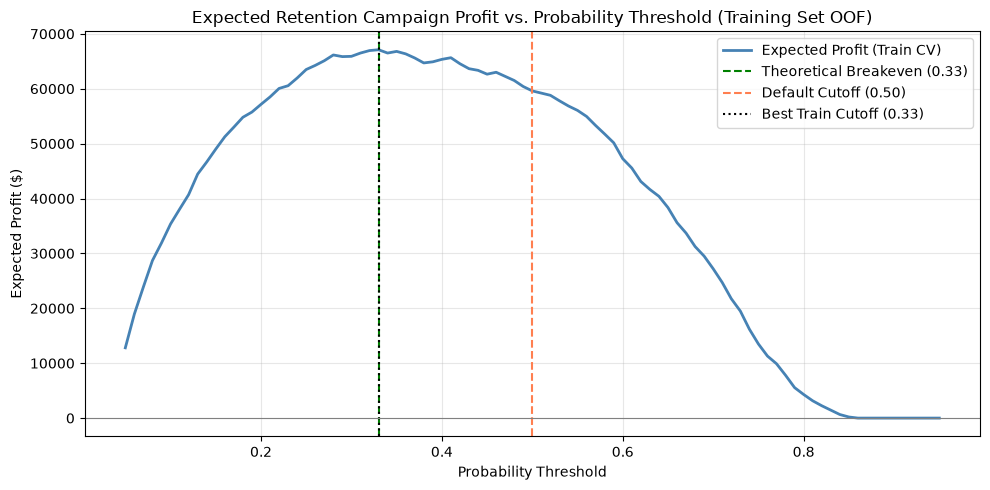


=== Final Hold-Out Test Set Strategy Comparison ===
                      Strategy  Customers Called  Real Churners Reached  Expected Profit ($)
Optimal Train Threshold (0.33)               500                    269                15350
      Default Threshold (0.50)               318                    209                15450
          Top 20% Highest Risk               281                    186                13850


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# 1. Get out-of-fold predicted probabilities on the TRAINING set only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_oof_probs = cross_val_predict(
    logreg_pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

# 2. Define the profit calculation function
def evaluate_profit(threshold, y_true, probs, call_cost=50, save_value=150):
    """
    Returns (customers_called, true_churners_reached, expected_profit).
    - Every called customer costs $50.
    - Every called customer who truly churned earns $150 (0.3 * $500).
    """
    called = probs >= threshold
    n_called = int(called.sum())
    n_true_churners = int((called & (y_true == 1)).sum())
    
    profit = (n_true_churners * save_value) - (n_called * call_cost)
    return n_called, n_true_churners, profit

# 3. Sweep thresholds from 0.05 to 0.95 in steps of 0.01 on training OOF probabilities
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep_results = []

for t in thresholds:
    n_called, n_saved, profit = evaluate_profit(t, y_train.values, train_oof_probs)
    sweep_results.append({
        "Threshold": t,
        "Called": n_called,
        "True_Churners": n_saved,
        "Profit": profit,
    })

sweep_df = pd.DataFrame(sweep_results)

# Find best threshold on training set and compare with 0.33
best_row = sweep_df.loc[sweep_df["Profit"].idxmax()]
row_033 = sweep_df.loc[sweep_df["Threshold"] == 0.33].iloc[0]

print("=== Training Set (Out-of-Fold CV) Threshold Comparison ===")
print(f"Best Threshold: {best_row['Threshold']:.2f} | Called: {int(best_row['Called'])} | True Churners: {int(best_row['True_Churners'])} | Profit: ${best_row['Profit']:,.0f}")
print(f"0.33 Threshold: {row_033['Threshold']:.2f} | Called: {int(row_033['Called'])} | True Churners: {int(row_033['True_Churners'])} | Profit: ${row_033['Profit']:,.0f}")

# 4. Plot Profit vs. Threshold on Training Set
plt.figure(figsize=(10, 5))
plt.plot(sweep_df["Threshold"], sweep_df["Profit"], color="steelblue", linewidth=2, label="Expected Profit (Train CV)")
plt.axvline(0.33, color="green", linestyle="--", linewidth=1.5, label="Theoretical Breakeven (0.33)")
plt.axvline(0.50, color="coral", linestyle="--", linewidth=1.5, label="Default Cutoff (0.50)")
plt.axvline(best_row["Threshold"], color="black", linestyle=":", linewidth=1.5, label=f"Best Train Cutoff ({best_row['Threshold']:.2f})")

plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Expected Retention Campaign Profit vs. Probability Threshold (Training Set OOF)")
plt.xlabel("Probability Threshold")
plt.ylabel("Expected Profit ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Apply the winning threshold ONCE to the unseen TEST set & compare strategies
best_t = float(best_row["Threshold"])
test_probs = logreg_pipe.predict_proba(X_test)[:, 1]
y_test_arr = y_test.values

# Strategy A: Optimal threshold chosen on train
t_called, t_churners, t_profit = evaluate_profit(best_t, y_test_arr, test_probs)

# Strategy B: Default 0.50 threshold
d_called, d_churners, d_profit = evaluate_profit(0.50, y_test_arr, test_probs)

# Strategy C: Top 20% highest-risk customers (from Ticket 2/3)
k = int(len(y_test_arr) * 0.20)
top20_cutoff = np.sort(test_probs)[::-1][k - 1]
top_called, top_churners, top_profit = evaluate_profit(top20_cutoff, y_test_arr, test_probs)

test_comparison = pd.DataFrame([
    {"Strategy": f"Optimal Train Threshold ({best_t:.2f})", "Customers Called": t_called, "Real Churners Reached": t_churners, "Expected Profit ($)": t_profit},
    {"Strategy": "Default Threshold (0.50)", "Customers Called": d_called, "Real Churners Reached": d_churners, "Expected Profit ($)": d_profit},
    {"Strategy": "Top 20% Highest Risk", "Customers Called": top_called, "Real Churners Reached": top_churners, "Expected Profit ($)": top_profit},
])

print("\n=== Final Hold-Out Test Set Strategy Comparison ===")
print(test_comparison.to_string(index=False))


In [5]:
import pandas as pd

# 1. Build a DataFrame of REAL churners only (using training OOF probabilities)
analysis_df = X_train.copy()
analysis_df["Churn"] = y_train.values
analysis_df["prob"] = train_oof_probs

real_churners = analysis_df[analysis_df["Churn"] == 1].copy()
real_churners["Status"] = real_churners["prob"].apply(
    lambda p: "Caught (prob >= 0.33)" if p >= 0.33 else "Missed (prob < 0.33)"
)

# 2. Count Caught vs. Missed out of total real churners
counts = real_churners["Status"].value_counts()
total_churners = len(real_churners)
missed_count = counts.get("Missed (prob < 0.33)", 0)
caught_count = counts.get("Caught (prob >= 0.33)", 0)

print("=== Real Churners Breakdown (Threshold = 0.33) ===")
print(f"Total Real Churners: {total_churners}")
print(f"Caught (>= 0.33):    {caught_count} ({caught_count / total_churners:.1%})")
print(f"Missed (< 0.33):     {missed_count} ({missed_count / total_churners:.1%})\n")

# 3. Side-by-side comparison on Contract, PaymentMethod, InternetService (%)
for col in ["Contract", "PaymentMethod", "InternetService"]:
    ct = pd.crosstab(real_churners[col], real_churners["Status"], normalize="columns") * 100
    print(f"--- {col} (% within each group) ---")
    print(ct.round(1))
    print()

# 4. Side-by-side medians for Tenure and MonthlyCharges
medians = real_churners.groupby("Status")[["tenure", "MonthlyCharges"]].median()
print("--- Median Tenure & MonthlyCharges ---")
print(medians.round(2))
print()

# 5. Inspect 30 Missed Churners directly
key_cols = ["Contract", "tenure", "PaymentMethod", "InternetService", "MonthlyCharges", "prob"]
missed_sample = (
    real_churners[real_churners["Status"] == "Missed (prob < 0.33)"][key_cols]
    .sort_values(by="prob", ascending=False)
    .head(30)
)

print("=== Sample of 30 Missed Churners ===")
print(missed_sample.to_string())


=== Real Churners Breakdown (Threshold = 0.33) ===
Total Real Churners: 1495
Caught (>= 0.33):    1106 (74.0%)
Missed (< 0.33):     389 (26.0%)

--- Contract (% within each group) ---
Status          Caught (prob >= 0.33)  Missed (prob < 0.33)
Contract                                                   
Month-to-month                   98.7                  60.2
One year                          1.3                  29.8
Two year                          0.0                  10.0

--- PaymentMethod (% within each group) ---
Status                     Caught (prob >= 0.33)  Missed (prob < 0.33)
PaymentMethod                                                         
Bank transfer (automatic)                   10.1                  22.9
Credit card (automatic)                      8.0                  23.7
Electronic check                            68.7                  27.0
Mailed check                                13.1                  26.5

--- InternetService (% within each group) --